# Value Iteration on Taxi-v4 (Zhao, Ch. 4, Algorithm 4.1)

In [1]:
!pip install -q "gymnasium[toy-text]>=1.3.0"


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

## Import `Taxi-v4` environment

In [3]:
env = gym.make(
    "Taxi-v4",
    is_rainy=True,            # Taxi slips laterally with (1 - rainy_probability) chance
    rainy_probability=0.8,    # Probability of moving in the intended direction
    fickle_passenger=False,    # Passenger may change destination after pickup
    #fickle_probability=0.3,   # Probability of destination change on first move
    render_mode="ansi"
)

In [4]:
env   = gym.make("Taxi-v4", is_rainy=False, fickle_passenger=False, render_mode="ansi")
u_env = env.unwrapped

In [5]:
env.reset()
print(env.render())

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




## Extracting model from environment

In [6]:
# from 00-taxi_v4_mdp.ipynb notebook
def mdp_arrays(u):
    nS, nA = u.observation_space.n, u.action_space.n
    P = np.zeros((nA, nS, nS))
    R = np.zeros((nS, nA))
    T = np.zeros((nA, nS, nS))
    for s in range(nS):
        for a in range(nA):
            for p, s2, r, t in u.P[s][a]:
                P[a, s, s2] += p
                R[s, a]     += p * r
                if t:
                    T[a, s, s2] += p
    return P, R, T

In [7]:
nS = u_env.observation_space.n
nA = u_env.action_space.n
P, R, T = mdp_arrays(u_env)

## Value Iteration Algorithm

In [8]:
Q = np.zeros((nS, nA))
V0 = np.zeros(nS)
V = np.zeros(nS)
pi = np.ones((nS, nA)) / nA
error = np.inf
MAX_ERROR = 1e-1
gamma = 0.99
Pc = P - T
K_MAX     = 1000
TOL       = 1e-8

SNAPSHOTS = np.arange(K_MAX)#[1, 10, 50, 100]
history = {}
errors  = []


def run_episode(pi, gamma, max_steps: int = 5000, seed: int = 42, render: bool = False):
    # RETURN: return, steps
    s, info = env.reset() #env.reset(seed=seed)

    k = 0
    g = 1
    term = False
    while not term and k < max_steps:
        a = np.argmax(pi[s])
        s, r, term, trunc, info = env.step(a)
        G = g*r
        g *= gamma
        if render:
            print(env.render())
        k += 1

    return G, k


# value iteration [Zhao, Algorithm 4.1]
for k in range(1, K_MAX + 1):
    V_old = V.copy()
    for s in range(nS):
        Q[s] = R[s]  + gamma*Pc[:, s, :]@V # P[a, s] = p(.|s, a)
        # for a in range(nA):
        #     try:
        #         # if s == 6:
        #         #     import pdb; pdb.set_trace()
        #         # print(s, a)
        #         Q[s, a] = R[s, a]  + gamma*P[a, s]@V # P[a, s] = p(.|s, a)
        #     except:
        #         import pdb; pdb.set_trace()

        a_star = np.argmax(Q[s])
        pi[s] = 0; pi[s, a_star] = 1
        V[s] = Q[s][a_star]

        
    err = np.max(np.abs(V - V_old))
    errors.append(err)

    print(f"k={k}", end="\r")
    if k in SNAPSHOTS or err < TOL:
        G, steps = run_episode(pi, gamma)
        history[k] = {"V": V.copy(), "Q": Q.copy(), "pi": pi.copy(), "episode": (G, steps)}   # copy, or later sweeps overwrite it

        if err < TOL:
            print(f"converged after {k} sweeps, error = {err:.2e}")
            break

print("snapshots:", sorted(history))

converged after 13 sweeps, error = 0.00e+00
snapshots: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


## Episode Reward and Size

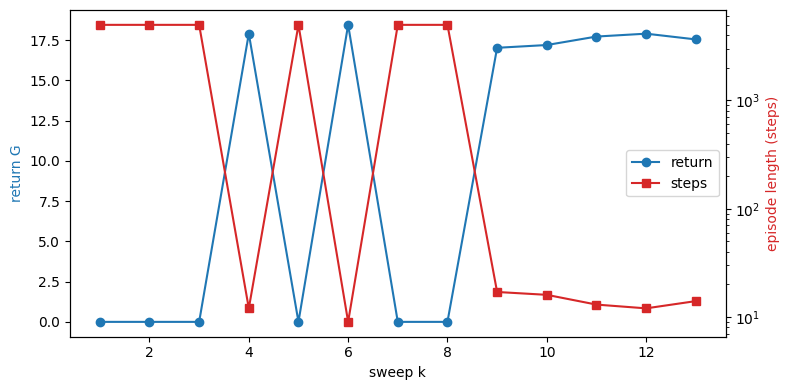

In [9]:
ks = sorted(history)

G_list = []
L_list = []
for k in ks:
    G, steps = history[k]["episode"]
    G_list.append(G)
    L_list.append(steps)

fig, ax1 = plt.subplots(figsize=(8, 4))
l1, = ax1.plot(ks, G_list, "-o", color="tab:blue", label="return")
ax1.set_xlabel("sweep k")
ax1.set_ylabel("return G", color="tab:blue")

ax2 = ax1.twinx()
ax2.set_yscale("log")
l2, = ax2.plot(ks, L_list, "-s", color="tab:red", label="steps")
ax2.set_ylabel("episode length (steps)", color="tab:red")

ax2.legend(handles=[l1, l2], loc="center right")   # one legend for both axes, drawn on top
fig.tight_layout()
plt.show()

## Testing Optimal Policy

In [10]:
run_episode(pi, gamma, render=True)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)

+---------+
|R: | : :G|
|_: | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

+---------+
|R: | : :G|
| : | : : |
|_: : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
|_| : | : |
|Y| : |B: |
+---------+
  (South)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)



(18.4548938885584, 9)